# Submitted By:

#### Name:               Arshia Fajar 
#### Reg No:            B23S0025DS001
#### Program:         BS Data Science (Spring 23)
#### Department:          IT & CS

# Submitted to:

#### Lab Instructor Name: Sir Jawad Safdar
#### Lab No:                   03
#### Subject:             Data Visualization Lab
#### Date:                 September 12th, 2025

In [4]:
import pandas as pd
import matplotlib.pyplot as plt


In [5]:
df=pd.read_csv(r"C:\Users\PMLS\Desktop\retail_sales_dataset.csv")
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


## Task 1: Monthly Sales Trend (Single Line Chart)

Scenario: A retail manager wants to see how the total sales revenue changes month by month.

Convert the Date column to datetime.

Group data by month and calculate the sum of Total Amount.

Plot a line chart showing monthly sales trend.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:

df["Date"] = pd.to_datetime(df["Date"])

In [10]:
df.dtypes

Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

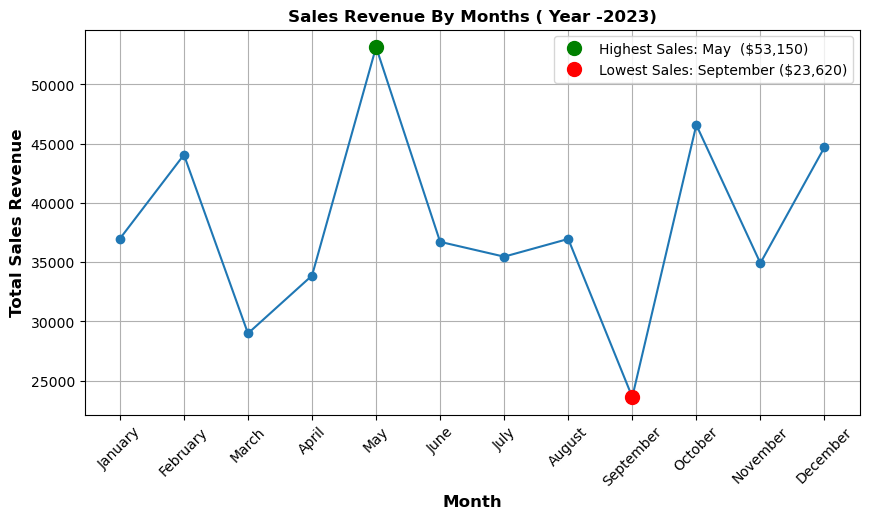

In [85]:

month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]  # defining the order of month


df["Month"] = df["Date"].dt.month_name()

revenue_by_months = df.groupby("Month")["Total Amount"].sum()

# calculating the revenue by each month
revenue_by_months = revenue_by_months.reindex(month_order) # making sure its sorted by month order given


max_month = revenue_by_months.idxmax() # we will use this for highlighting
max_revenue = revenue_by_months.max()
min_month= revenue_by_months.idxmin()
min_revenue= revenue_by_months.min()


plt.figure(figsize=(10,5))
plt.plot(revenue_by_months.index, revenue_by_months.values, marker='o') 
plt.plot(max_month, max_revenue, 'go', markersize=10, label=f'Highest Sales: {max_month}  (${max_revenue:,.0f})')
plt.plot(min_month, min_revenue, 'ro', markersize=10, label=f'Lowest Sales: {min_month} (${min_revenue:,.0f})') 
plt.title("Sales Revenue By Months ( Year -2023)", fontweight="bold")
plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.xticks(rotation= 45)
plt.ylabel("Total Sales Revenue", fontsize=12, fontweight="bold")
plt.legend()
plt.grid(True)
plt.show()



## Conclusion:
- By looking at above graph, we can see the month with the highest sales / revenue is " May " having a revenue of aroung 59000 or 60000.
- and the lowest dip in the revenue is in september which is even below 25000.

- From this, we know brands can plan promotions and discount offers in September to boost sales
- while in May they can take advantage of the high demand by pushing premium products or launching new arrivals.
- And from further analysis and knowing which category is sold the most, we can boost the promotions or sales on that particular category. Also, knowing which category is least bought in september that leads to decline of overalll sales in september, we can make a proper stragtegy to boost sales in september.


### -------------------------------------------------------------------------------

## Task 2: Sales Trend by Product Category (Multi-Line Chart)

Scenario: The company wants to compare different product categories to see which products sell more over time.

Group data by month and product category.

Plot a multi-line chart, where each line represents a product category’s monthly sales.

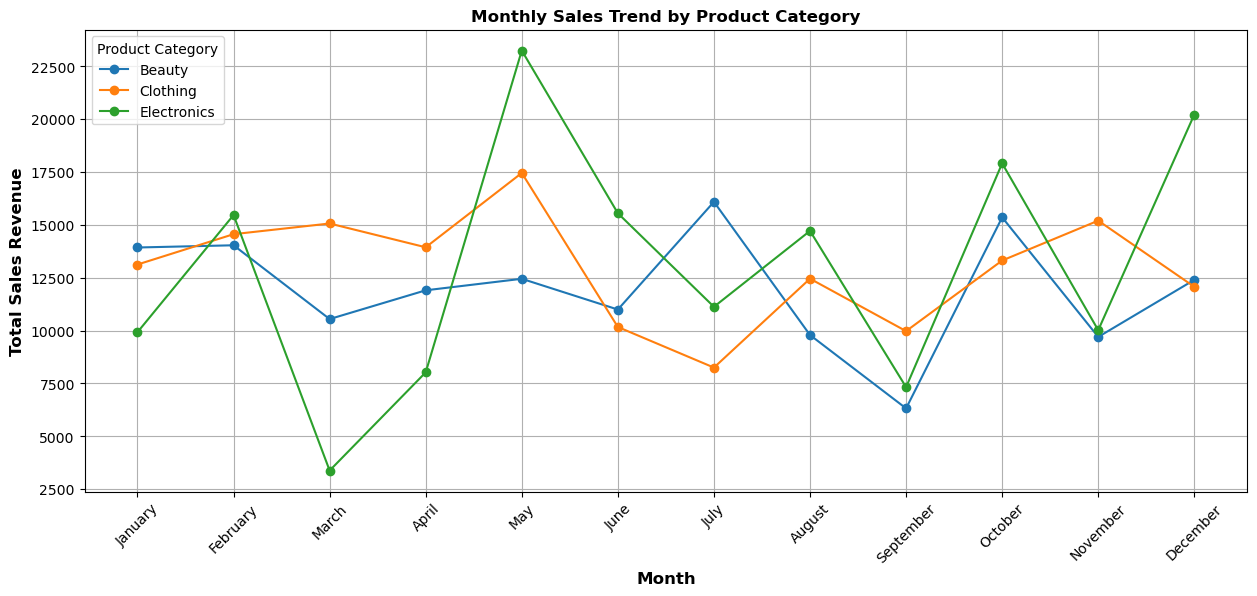

In [121]:

month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
df["Month"] = df["Date"].dt.month_name()

sales_by_category = df.groupby(["Month", "Product Category"])["Total Amount"].sum().unstack()

sales_by_category = sales_by_category.reindex(month_order)

sales_by_category.plot(kind="line", marker="o", figsize=(15,6), grid=True)

    
plt.title("Monthly Sales Trend by Product Category", fontsize=12, fontweight="bold")
plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.ylabel("Total Sales Revenue",  fontsize=12, fontweight="bold")
plt.xticks(range(len(sales_by_category.index)), sales_by_category.index, rotation=45)
plt.legend(title="Product Category")
plt.show()


#### Electronics:

Electronics shows the highest revenue peaks among all categories but also the sharp loss as well ( as in march).
- May (23k) is  the strongest month overall and December (20k) is second peak which may be  aligned with year-end demands like holiday promotions, product launches, or gifting seasons like Chrismas ( 25 december ) and mother's day.
- March (3.4k) had the major drop which may indicate lack of seasonal demand or no special event.

#### Clothing:

If we look at clothing it shows stable and consistent sales performance throughout the year. 
- Highets sales were in May. It may be due to summer sales, summer discount on brand and season shft.
- Second highest is in November (15.2k) which also shows that there may be pre winter demand as well.
- July (8.3k) reflects the lowest point, possibly due to mid-summer slowdown in apparel shopping. June and July are the month of extreme heat and usually deals and dicounts are started by brand in september and october.

##### Beauty

Beauty has  a steady sales just like clothing  with moderate peaks but doesn't have deep declines.
- July (16.2k) is the strongest month which may be  may be related  to summer demand, discount campaigns, and offers targeting young adults and university students before academic sessions resume.
- October (15.4k) shows another significant rise. This may be linked to wedding seasons. January (14k) is also strong, showsthe “new year, new you” effect (especifically skin care brand ).
- September (6.4k) is the lowest month, which may indicate a seasonal decrease in beauty spending.

Electronics shows strong seasonal demand with big peaks but sharp dips. Clothing stays stable year-round.  Beauty provides steady support, with moderate peaks and no deep declines.

- So we can say Electronics sell more over time with high revenue generating category. After identifying it's peak months, we know when to run promotional ads, social media campaigns to promote a particular new thing in the market.

### Note:

### Alternate graph to compare  different product categories sales over time.


- Alternate graph is the grouped bar chart. This makes it easy to see the trend of a category bought in a month, along with other comparative categories as well. Because just seeing looking for revenues for a categories in a month side by side is way easier than tracking three different lines and remembering their revenue.

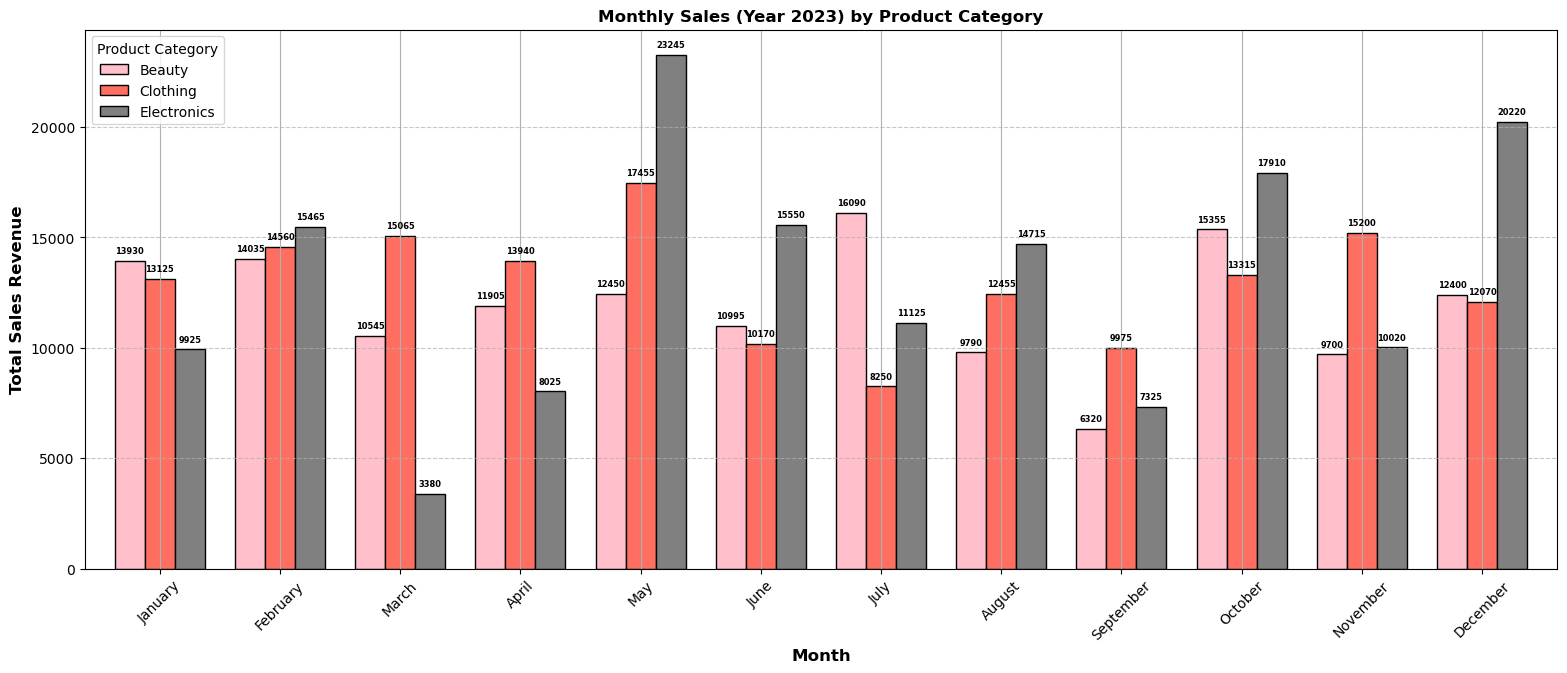

In [12]:

month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
df["Month"] = df["Date"].dt.month_name()
# group by month and product category over the total sales.  unstack
sales_by_category = df.groupby(["Month", "Product Category"])["Total Amount"].sum().unstack()  # month | Clothing | Beauty | Electronics  # unstack makes columns

# reindex to enforce Jan to  Dec
sales_by_category = sales_by_category.reindex(month_order)


colors = ["#FFC0CB", "#FF6F61", "#808080"]

# plot grouped bar char
result = sales_by_category.plot(kind="bar", figsize=(19,7), color=colors[:len(sales_by_category.columns)], edgecolor= "black",grid=True, width =0.75)  # match num of categories)

plt.title("Monthly Sales (Year 2023) by Product Category", fontweight="bold")
plt.xlabel("Month", fontsize=12,  fontweight="bold")
plt.ylabel("Total Sales Revenue", fontsize=12,  fontweight="bold")
plt.legend(title="Product Category")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)


for container in result.containers: # going through all bars
    result.bar_label(container, fmt="%.0f", label_type="edge", fontsize=6, padding =4, fontweight="bold") #formating numbers with no decimals. .bar_labels add text label to bar

plt.show()


## Conclusion:

While the multi-line graph clearly shows the trend of each category over the months, the grouped bar chart makes it much easier to compare sales across categories in a given month. The numbers displayed on the bars allow anyone, even someone seeing the graph for the first time too, to  immediately understand the differences in sales quantities between categories.

- For identifying the increasing or decreasing trend of a categories over time, the multi-line graph is still preferable. However, if we want to know that 23,245 Electronics products were sold in May, and compare it with the sales of other categories in the same month. the grouped bar chart is far more effective.

### --------------------------------------------------------------------------------------------------

## Task 3: Average Customer Spending by Gender (Multi-Line Chart)

Scenario: The marketing team wants to know if males and females spend differently over time.

Group data by month and gender, taking the average of Total Amount.

Plot a multi-line chart with two lines (Male vs Female) showing spending patterns over time.

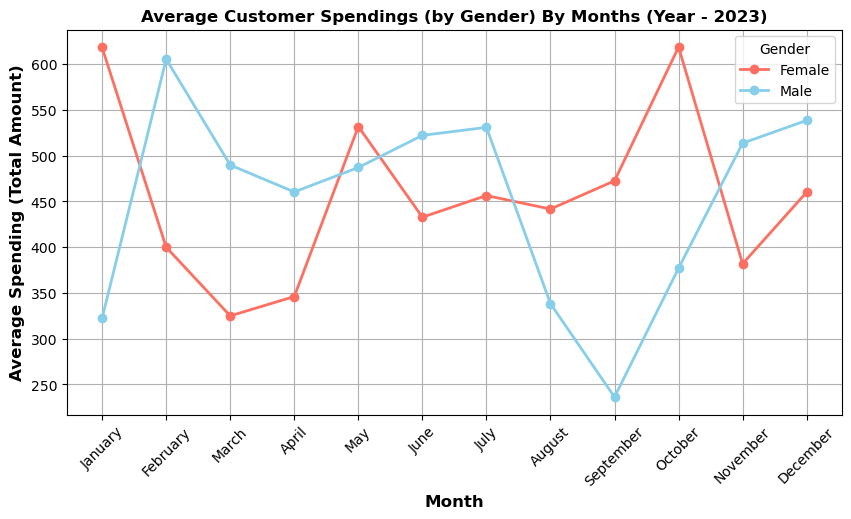

In [15]:


# defining teh orderorder
month_order = ["January","February","March","April","May","June","July","August","September","October","November","December"]
df["Month"] = df["Date"].dt.month_name()
#df["Month"] = pd.Categorical(df["Month"], categories=month_order, ordered=True)


# grouping  by Month + Gender → average of Total Amount
# unstack makes the column of both gender and their average spending by month are the values 
avg_spending = df.groupby(["Month", "Gender"])["Total Amount"].mean().unstack()

# reindex so results are in correct order of  the months 
avg_spending = avg_spending.reindex(month_order)


colors=["#FF6F61", "skyblue"]# defined color
result = avg_spending.plot(kind="line", marker="o", figsize=(10,5), linewidth=2,  color=colors[:len(avg_spending.columns)],grid=True) # it pick colors matching number of columns (so 2 genders  so 2 colors).

plt.title("Average Customer Spendings (by Gender) By Months (Year - 2023)", fontsize= 12, fontweight="bold")
plt.xlabel("Month", fontsize= 12, fontweight="bold")
plt.ylabel("Average Spending (Total Amount)", fontsize= 12, fontweight="bold")
plt.xticks(range(len(avg_spending.index)),avg_spending.index, rotation=45)
plt.legend(title="Gender")
plt.xticks(rotation=45)


plt.show()


## Conclusion:
##### For females:

The highest spending by female sector is in New year start and around October,Females respond strongly to festive/wedding season offers (January, May, October). Campaigns targeting beauty, fashion, and clothings during these months will perform the best.

##### for males:
The males spending lines show that they spend the most in Feb, mid year (June) and Dec ( end of the year). And since males are more interested in gadgets, electronics ( mobile phones, PCs ) So, promotion of these products in these durations would work the best.

##### In september: 
September is the dead month for sales ( from the 1st task graph) and specifically for males. So, brands can use this month to sell their old stocked products by applying discount sales. 
- For instance if we look at the clothing sector in general, they can apply a small discount on the original price. This makes people feel like it’s a big discount on a good product and creates the urge to buy. Just like Sapphire and Khaadi normally do on their old stocked clothing.
- We can do this for male products as well.

### --------------------------------------------------------------------------------

## Task 4: Quantity Sold vs. Price Trend (Dual Axis Line Chart)

Scenario: The inventory team wants to analyze the relationship between total quantity sold and average price per unit over time.

Group data by month.

Calculate total Quantity and average Price per Unit.

Plot a dual-axis line chart:

X-axis: Month

Left Y-axis: Quantity Sold (line 1)

Right Y-axis: Average Price (line 2)

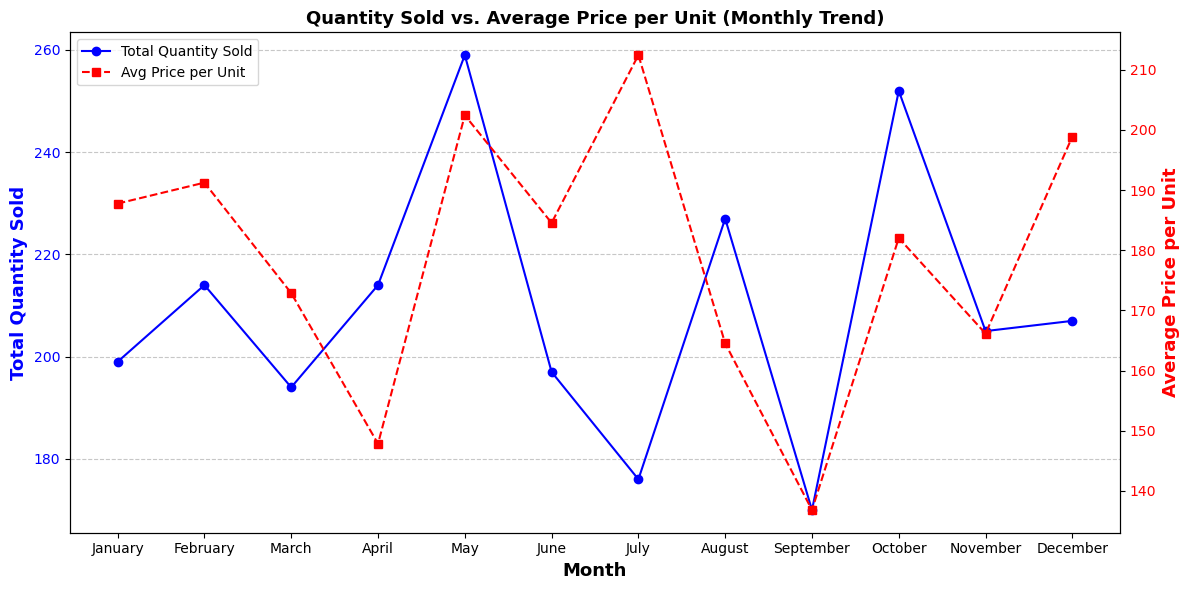

In [159]:


# grouping the d data by month ---
monthly_data = df.groupby("Month_Name").agg({"Quantity": "sum","Price per Unit": "mean"}).reindex(month_order)

#first it grabes the months names we defined above.
# and  then for each month it sums the Quantity and averages the Price per Unit,
# and finally it reorders the results so the months appear in Jan too Dec order.

# firts we defined the whole  figure 
# and ax1 = the first axis inside it (for left Y-axis).
fig, ax1 = plt.subplots(figsize=(12,6))

# Left Y-axis  is defined fo rQuantity
ax1.plot(monthly_data.index, monthly_data["Quantity"], color="blue", marker="o", label="Total Quantity Sold") # on x axis months names, on y their quantity)
ax1.set_xlabel("Month", fontsize= 13, fontweight="bold") 
ax1.set_ylabel("Total Quantity Sold", color="blue", fontsize= 13, fontweight="bold")
ax1.tick_params(axis="y", labelcolor="blue") # it colors the numbers on the left Y-axis (like 10k, 20k) blue .

# Right Y-axis  which shows averagep pprice


ax2 = ax1.twinx() # this creates a second Y-axis (ax2) that shares the same X-axis (months) as ax1. graph has two Y-axes: Left= Quantity, Righh= Price
ax2.plot(monthly_data.index, monthly_data["Price per Unit"], color="red", marker="s", linestyle="--", label="Avg Price per Unit")

# price is placed on y axis, line style is changed. line style is diffferent as well.

ax2.set_ylabel("Average Price per Unit", color="red", fontsize= 13, fontweight="bold")
ax2.tick_params(axis="y", labelcolor="red")

plt.title("Quantity Sold vs. Average Price per Unit (Monthly Trend)", fontsize= 13, fontweight="bold")
ax1.grid(axis="y", linestyle="--", alpha=0.7)


lines, labels = ax1.get_legend_handles_labels()  # it grrabs the line styles a nd labels from the first axis (ax1).
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines + lines2, labels + labels2, loc="upper left") # for legends it combines both line styles and labels and location

#plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Conclusion:

#### Low Price, High Sales
In normal cases, when the price per unit goes up or increases, the number of products sold is usually low.This is the typical economic relationship that  as the price increases, the quantity that people are willing and able to buy decreases.

- This is what is happening in July. The average price per unit has exceeded 210  and thus the number of products sold went downhill means the nube of products sold decreased to a dangerous level.
- This is what happpened in Dec as well because the average price directly increased from NOV to DEC and thus sales also decreased.

#### High Price, Low Sales
The above is normal but when the opposite happens as well like price of a product increases yet the sales increase as well instead of decreasing.

- In May, the average price per unit increased significantly compared to April, and instead of sales decreasing, they also spiked to their highest point on the chart.

- This may happens due to:

- Major marketing campaign, a special event, or a new product launch that has the customer interetsted that they are paying a huge amount as well.
- Or it may be a  peak season for the  particular product, leading to high demand regardless of the price increase.
- Or The product might be so popular or have such a loyal customer base that people are willing to pay a higher price. ( Saphire etc).

#### Low Price, Low Sales
In September, both the total quantity sold and the average price per unit dropped dramatically to their lowest points on the entire chart.

- This indicates a significant low demand  in the market for a product. 
- Or September might mark the end of a high-demand season like the summer which is causing both price and sales to fall off a cliff.
- Or there might be bad reviews, bycott or a scandel that has caused the product downfall and sales downfall as well even tho its price has decreased.
- A new competitor might have entered the market with a better or cheaper product, forcing this product's price and sales to plummet.